# 03. IntentGuard 기록 재집계

이 프로젝트는 IntentGuard에서 시작했다. 거기서 README에 적은 수치를 이 레포의 파이프라인(pandas)으로 다시 계산해서
원래 수치와 같은지 확인한다. 같아야 2층 결과를 IntentGuard 결과와 나란히 놓을 수 있다.

입력은 `pnpm import:intentguard`가 만든 `analysis/data/intentguard/`의 CSV다.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # analysis/에서 실행한다
import pandas as pd
import matplotlib.pyplot as plt
from common import *

setup_style()
pd.set_option("display.max_colwidth", 90)

In [2]:
src = DATA / "intentguard"
controlled = pd.read_csv(src / "controlled-90.csv")
multi = pd.read_csv(src / "multi-model-80.csv")
dugout = pd.read_csv(src / "dugout-16.csv")
reported = load_json(src / "reported.json")
len(controlled), len(multi), len(dugout)

(90, 80, 16)

## 1. 통제 실험 90회 (Claude Code, 과제 10개 × 경로 3개 × 3회)

확인된 성공은 "실제로 성공했고, 답변 검수에서 결과를 확인했다고 본 실행"이다.

In [3]:
PATHS = ["mcp", "web-v1", "web-v2"]
g = controlled.groupby("path")
recount = pd.DataFrame({
    "n": g.size(),
    "success": g.success.sum(),
    "verified": g.verified.sum(),
    "mean turns": g.turns.mean().round(1),
}).loc[PATHS]
recount["reported verified"] = pd.Series(reported["controlled"]["verified"])
recount["reported mean turns"] = pd.Series(reported["controlled"]["mean_turns"])
recount["matches"] = (recount.verified == recount["reported verified"]) & (recount["mean turns"] == recount["reported mean turns"])
recount

,n,success,verified,mean turns,reported verified,reported mean turns,matches
path,,,,,,,
mcp,30,30,22,4.6,22,4.6,True
web-v1,30,28,16,25.7,16,25.7,True
web-v2,30,30,30,14.8,30,14.8,True


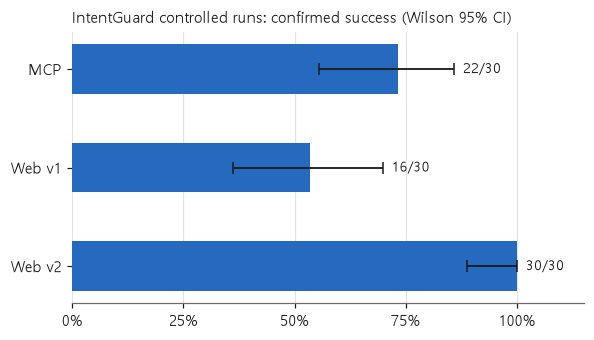

In [4]:
ci = recount.apply(lambda r: wilson(r.verified, r.n), axis=1, result_type="expand")
rate = recount.verified / recount.n

fig, ax = plt.subplots(figsize=(6, 3.2))
y = range(len(PATHS))
ax.barh(y, rate, color=BLUE, height=0.5)
ax.errorbar(rate, y, xerr=[rate - ci[0], ci[1] - rate], fmt="none", ecolor=INK, capsize=4, lw=1.2)
for i, p in enumerate(PATHS):
    ax.text(ci[1].iloc[i] + 0.02, i, f"{int(recount.verified.iloc[i])}/{int(recount.n.iloc[i])}", va="center", fontsize=9, color=INK)
ax.set_yticks(list(y), ["MCP", "Web v1", "Web v2"])
ax.invert_yaxis()
ax.set_xlim(0, 1.15)
ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="x", color="#e4e3df", lw=0.8)
ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.set_title("IntentGuard controlled runs: confirmed success (Wilson 95% CI)", loc="left", fontsize=10, color=INK)
fig.savefig(FIGURES / "intentguard-verified.png")
plt.show()

In [5]:
from scipy.stats import fisher_exact

def two_by_two(a, b, col="verified"):
    return [[int(a[col].sum()), int((~a[col]).sum())], [int(b[col].sum()), int((~b[col]).sum())]]

t = two_by_two(controlled[controlled.path == "web-v1"], controlled[controlled.path == "web-v2"])
res = fisher_exact(t)
print(f"Web v1 vs v2 확인된 성공: {t}, Fisher 정확 검정 p = {res.pvalue:.1e}")

Web v1 vs v2 확인된 성공: [[16, 14], [30, 0]], Fisher 정확 검정 p = 1.7e-05


## 2. 모델 4종 교차 검증 80회 (Antigravity CLI)

v1과 v2가 모두 끝난 쌍만 비교했으므로 ui별로 40회씩이다.

In [6]:
m = multi.assign(confirmed=multi.outcome == "confirmed-success")
by_model = m.pivot_table(index="model", columns="ui", values="confirmed", aggfunc="sum")
by_model.loc["전체"] = by_model.sum()
by_model["reported"] = ""
by_model.loc["전체", "reported"] = f"{reported['multi_model']['v1_confirmed']} → {reported['multi_model']['v2_confirmed']}"
by_model

ui,v1,v2,reported
model,,,
claude-sonnet-5-5-low,2,9,
gemini-3.8-flash-low,8,9,
gemini-4-argon-low,7,9,
gpt-oss-120b-medium,3,6,
전체,20,33,20 → 33


In [7]:
m.groupby("ui").outcome.value_counts().unstack(fill_value=0)

outcome,confirmed-success,failure,false-failure,false-success,unconfirmed-success
ui,,,,,
v1,20,7,2,5,6
v2,33,1,0,3,3


## 3. MY DUGOUT 결함 수정 전후 16회

수정 후 빌드는 사람 기준 E2E 5개를 모두 통과했지만 에이전트 성공은 그대로였다.
`target_not_found`는 에이전트가 스냅샷에서 받은 ref를 눌렀는데 그 요소를 찾지 못하고 기다린 횟수다.

In [8]:
d = dugout.assign(success=dugout.outcome == "confirmed-success")
summary = d.groupby("build").agg(
    n=("success", "size"), success=("success", "sum"),
    game_started=("game_started", "sum"), settings_saved=("settings_saved", "sum"),
    target_not_found=("target_not_found", "sum"),
).loc[["before", "after"]]
summary["reported success"] = [reported["dugout"]["before_success"], reported["dugout"]["after_success"]]
summary

,n,success,game_started,settings_saved,target_not_found,reported success
build,,,,,,
before,8,6,6,6,0,6
after,8,6,6,8,4,6


In [9]:
d[d.model.str.startswith("gpt-oss")][["build", "outcome", "game_started", "settings_saved", "steps", "target_not_found"]]

,build,outcome,game_started,settings_saved,steps,target_not_found
3,before,false-success,False,False,24,0
7,before,failure,False,False,34,0
14,after,false-success,False,True,29,3
15,after,failure,False,True,19,1


- 수정 전후 성공은 6/8과 6/8로, README 수치와 같다. 실패는 두 빌드 모두 GPT-OSS 2회다.
- 실패의 내용은 바뀌었다. 수정 후에는 설정 저장은 채웠지만(시트 안 선택 상태가 `aria-pressed`로 드러남)
  경기 시작을 못 했고, 수정 전에는 없던 `target_not_found`가 생겼다. 배경을 inert로 막자 스냅샷에 남은 배경 버튼의 ref가
  눌리지 않는 대상이 된 것이다. 이 관찰이 1층 매트릭스의 "모달 + 배경 inert·aria-hidden" 행으로 이어졌다.
- 모델별 2회라 성공률 비교로 읽지 않는다.